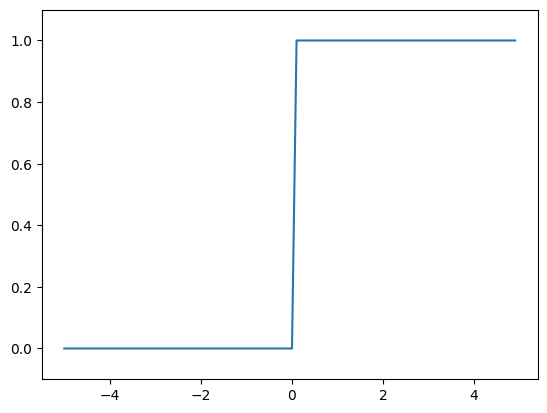

In [1]:
# 跃阶函数的可视化
import matplotlib.pyplot as plt
import numpy as np


def step_function(x):
    return np.array(x > 0, dtype=int)


x = np.arange(-5.0, 5.0, 0.1)
y = step_function(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()


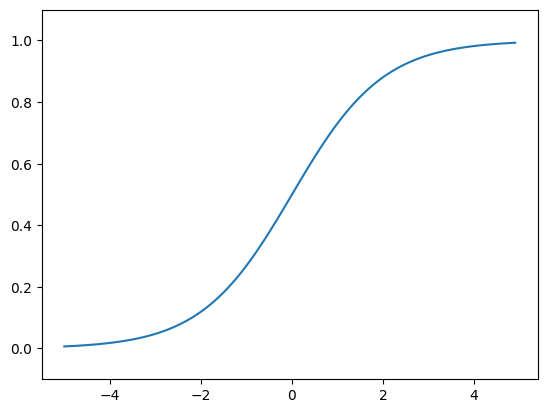

In [2]:
# sigmoid函数的实现与可视化
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


x = np.arange(-5.0, 5.0, 0.1)
y = sigmoid(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

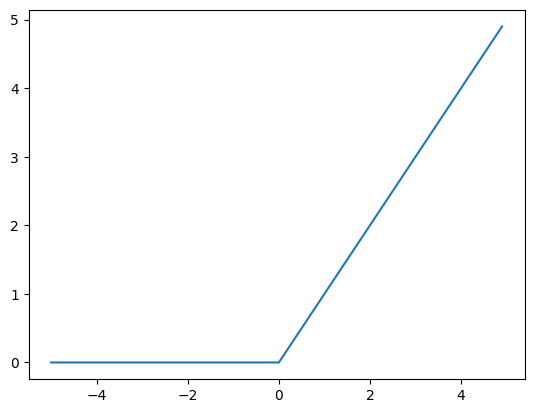

In [3]:
# ReLU 函数的实现和可视化
def relu(x):
    return np.maximum(0, x)


x = np.arange(-5.0, 5.0, 0.1)
y = relu(x)
plt.plot(x, y)
plt.show()

In [4]:
import numpy as np

A = np.array([1, 2, 3, 4])
A, np.ndim(A), A.shape, A.shape[0]

B = np.array([[1, 2], [3, 4], [5, 6]])
B, np.ndim(B), B.shape

(array([[1, 2],
        [3, 4],
        [5, 6]]),
 2,
 (3, 2))

In [5]:
# 矩阵乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
np.dot(A, B), A, B

(array([[19, 22],
        [43, 50]]),
 array([[1, 2],
        [3, 4]]),
 array([[5, 6],
        [7, 8]]))

In [6]:
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2], [3, 4], [5, 6]])
np.dot(A, B)

array([[22, 28],
       [49, 64]])

In [7]:
# 使用 NumPy 矩阵来实现神经网络
X = np.array([1, 2])
W = np.array([[1, 3, 5], [2, 4, 6]])
X.shape, W.shape  # noqa: B018
Y = np.dot(X, W)
Y

array([ 5, 11, 17])

In [8]:
# 用 NumPy 多维数组来实现式 （ 3 . 9 ）
X = np.array([1.0, 0.5])
W1 = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
B1 = np.array([0.1, 0.2, 0.3])
W1.shape, X.shape, B1.shape  # noqa: B018

A1 = np.dot(X, W1) + B1
Z1 = sigmoid(A1)
# print(A1)
# print(Z1)

# 实现第 1 层到第 2 层的信号传递
W2 = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
B2 = np.array([0.1, 0.2])
A2 = np.dot(Z1, W2) + B2
Z2 = sigmoid(A2)
Z1, Z2

(array([0.57444252, 0.66818777, 0.75026011]), array([0.62624937, 0.7710107 ]))

In [9]:
# 第 2 层到输出层的信号传递
def identity_function(x):
    return x


W3 = np.array([[0.1, 0.3], [0.2, 0.4]])
B3 = np.array([0.1, 0.2])

A3 = np.dot(Z2, W3) + B3
Y = identity_function(A3)
Y

array([0.31682708, 0.69627909])

In [10]:
# 代码实现小结
def init_network():
    network = {}
    network["W1"] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
    network["b1"] = np.array([0.1, 0.2, 0.3])
    network["W2"] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
    network["b2"] = np.array([0.1, 0.2])
    network["W3"] = np.array([[0.1, 0.3], [0.2, 0.4]])
    network["b3"] = np.array([0.1, 0.2])

    return network


def forword(network, x):
    W1, W2, W3 = network["W1"], network["W2"], network["W3"]
    b1, b2, b3 = network["b1"], network["b2"], network["b3"]

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = identity_function(a3)

    return y


network = init_network()
x = np.array([1.0, 0.5])
y = forword(network, x)
y

array([0.31682708, 0.69627909])

In [11]:
# softmax函数
def softmax(a):
    c = np.max(a)
    exp_a = np.exp(a - c)
    sum_exp_a = np.sum(exp_a)
    y = exp_a / sum_exp_a

    return y

In [12]:
a = np.array([0.3, 2.9, 4.0])
y = softmax(a)
y, np.sum(y)

(array([0.01821127, 0.24519181, 0.73659691]), 1.0)

In [ ]:
# 下载mnist数据集
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np

path = Path("data/minist.npz")
path.parent.mkdir(parents=True, exist_ok=True)

# 没有就下载数据集
if not path.exists():
    url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
    urlretrieve(url, path)

In [ ]:
# 读取数据集
with np.load(path, allow_pickle=False) as data:
    x_train = data["x_train"]
    t_train = data["y_train"]
    x_test = data["x_test"]
    t_test = data["y_test"]

# 将每张 28×28 的图片展开成长度为 784 的一维数组
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print(x_train.shape)
print(t_train.shape)
print(x_test.shape)
print(t_test.shape)

(60000, 784)
(60000,)
(10000, 784)
(10000,)


In [ ]:
# 显示 MNIST 图像
from IPython.display import display
from PIL import Image

# 取出第一张图片及其标签
img = x_train[0]
label = t_train[0]

label, img.shape  # noqa: B018


# 将一维数组还原成 28×28 的图片
img = img.reshape(28, 28)

# 在 Notebook 中直接显示图片
display(Image.fromarray(img))

In [ ]:
def get_data():
    x = x_test.astype(np.float32) / 255.0

    return x, t_test


import pickle


def init_network():
    path = Path("data/sample_weight.pkl")
    path.parent.mkdir(parents=True, exist_ok=True)

    if not path.exists():
        url = (
            "https://raw.githubusercontent.com/oreilly-japan/"
            "deep-learning-from-scratch/master/ch03/sample_weight.pkl"
        )
        urlretrieve(url, path)

    with path.open("rb") as f:
        network = pickle.load(f)

    return network


def predict(network, x):
    W1, W2, W3 = network["W1"], network["W2"], network["W3"]
    b1, b2, b3 = network["b1"], network["b2"], network["b3"]

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = softmax(a3)

    return y

In [ ]:
x, t = get_data()
network = init_network()

accuracy_cnt = 0
for i in range(len(x)):
    y = predict(network, x[i])
    p = np.argmax(y)
    if p == t[i]:
        accuracy_cnt += 1

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

Accuracy:0.9352


In [ ]:
W1, W2, W3 = network["W1"], network["W2"], network["W3"]

# 输出刚才的神经网络的各层的权重的形状
x.shape, x[0].shape, W1.shape, W2.shape, W3.shape

((10000, 784), (784,), (784, 50), (50, 100), (100, 10))

In [ ]:
# 进行基于批处理的代码实现
x, t = get_data()
network = init_network()

batch_size = 100  # 批数量
accuracy_cnt = 0

for i in range(0, len(x), batch_size):
    x_batch = x[i : i + batch_size]
    y_batch = predict(network, x_batch)
    p = np.argmax(y_batch, axis=1)
    accuracy_cnt += np.sum(p == t[i : i + batch_size])

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

Accuracy:0.9352


In [ ]:
# axis 指定沿哪个方向比较，argmax 返回最大值的位置，位置从 0 开始。沿着某个轴的方向走
x = np.array([[0.1, 0.8, 0.1], [0.3, 0.1, 0.6], [0.2, 0.5, 0.3], [0.8, 0.1, 0.1]])
y = np.argmax(x, axis=1)
x, y

(array([[0.1, 0.8, 0.1],
        [0.3, 0.1, 0.6],
        [0.2, 0.5, 0.3],
        [0.8, 0.1, 0.1]]),
 array([1, 2, 1, 0], dtype=int64))